# Datos Faltantes

In [3]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [5]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
48,0.067136,0.050680,-0.041774,0.011544,0.002559,0.005889,0.041277,-0.039493,-0.059471,-0.021788,75.0
416,-0.027310,-0.044642,0.080019,0.098751,-0.002945,0.018101,-0.017629,0.003312,-0.029526,0.036201,257.0
302,0.012648,-0.044642,0.033673,0.033337,0.030078,0.027183,-0.002903,0.008847,0.031193,0.027917,198.0
72,0.063504,0.050680,-0.004050,-0.012556,0.103003,0.048790,0.056003,-0.002592,0.084492,-0.017646,202.0
252,0.005383,-0.044642,0.059541,-0.056177,0.024574,0.052861,-0.043401,0.050914,-0.004222,-0.030072,91.0
431,0.070769,0.050680,-0.030996,0.021872,-0.037344,-0.047034,0.033914,-0.039493,-0.014960,-0.001078,66.0
378,0.016281,0.050680,0.002417,-0.005670,-0.005697,0.010899,-0.050764,0.034309,0.022688,-0.038357,245.0
248,-0.041840,-0.044642,0.047685,0.059744,0.127771,0.128016,-0.024993,0.108111,0.063890,0.040343,258.0
339,0.027178,-0.044642,-0.007284,-0.050427,0.075484,0.056619,0.033914,-0.002592,0.043444,0.015491,95.0
305,-0.009147,0.050680,-0.039618,-0.040099,-0.008449,0.016222,-0.065491,0.071210,0.017765,-0.067351,124.0


In [6]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [7]:
missing_values = data.isna().sum()
print(missing_values)

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64


### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [8]:
from sklearn.impute import SimpleImputer

imputer_simple = SimpleImputer(strategy='mean')
data['bmi_simple'] = imputer_simple.fit_transform(data[['bmi']])

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [9]:
from sklearn.impute import KNNImputer

knn_imputer = KNNImputer(n_neighbors=5)
data[['bmi_knn', 'bp_knn']] = knn_imputer.fit_transform(data[['bmi', 'bp']])

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

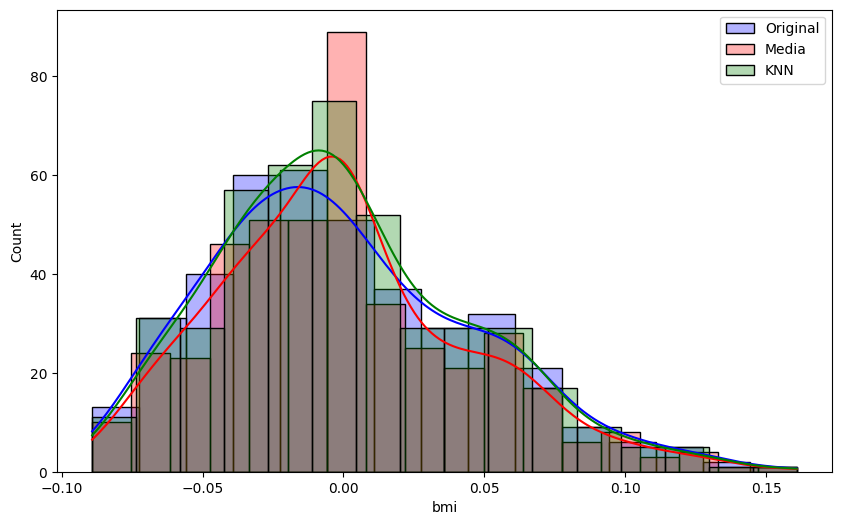

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.histplot(data['bmi'].dropna(), label='Original', kde=True, color='blue', alpha=0.3)
sns.histplot(data['bmi_simple'], label='Media', kde=True, color='red', alpha=0.3)
sns.histplot(data['bmi_knn'], label='KNN', kde=True, color='green', alpha=0.3)
plt.legend()
plt.show()